In [1]:
# Rank Names
RANKS = {
    'BEGINNER': 'Beginner',
    'POKEBALL': 'Pokeball',
    'GREATBALL': 'Greatball',
    'ULTRABALL': 'Ultraball',
    'MASTERBALL': 'Masterball'
}

# Points required for each rank
RANK_THRESHOLDS = {
    'BEGINNER_1': 0,
    'BEGINNER_2': 20,
    'BEGINNER_3': 50,
    'BEGINNER_4': 95,
    'POKEBALL_1': 145,
    'POKEBALL_2': 195,
    'POKEBALL_3': 245,
    'POKEBALL_4': 300,
    'GREATBALL_1': 355,
    'GREATBALL_2': 420,
    'GREATBALL_3': 490,
    'GREATBALL_4': 600,
    'ULTRABALL_1': 710,
    'ULTRABALL_2': 860,
    'ULTRABALL_3': 1010,
    'ULTRABALL_4': 1225,
    'MASTERBALL': 1450
}

# Points gained/lost per match
POINTS_WIN = 10
POINTS_LOSS = {
    'BEGINNER': 0,
    'POKEBALL': 5,
    'GREATBALL': 5,
    'ULTRABALL': 7,
    'MASTERBALL': 10
}

# Consecutive win bonus settings
CONSECUTIVE_WIN_BONUS = 3
MAX_CONSECUTIVE_WIN_BONUS = 12
MAX_CONSECUTIVE_WINS_FOR_BONUS = 4  # This will give max bonus of 12 (3 * 4)

# Rank progression
RANK_PROGRESSION = [
    'BEGINNER_1', 'BEGINNER_2', 'BEGINNER_3', 'BEGINNER_4',
    'POKEBALL_1', 'POKEBALL_2', 'POKEBALL_3', 'POKEBALL_4',
    'GREATBALL_1', 'GREATBALL_2', 'GREATBALL_3', 'GREATBALL_4',
    'ULTRABALL_1', 'ULTRABALL_2', 'ULTRABALL_3', 'ULTRABALL_4',
    'MASTERBALL'
] 

In [2]:
import numpy as np

In [3]:
def calculate_rank_progression(match_results):
    points = 0
    current_rank = 'BEGINNER_1'
    consecutive_wins = 0
    rank_history = []
    points_history = []
    
    for result in match_results:
        # Calculate points for this match
        if result == 1:  # Win
            points += POINTS_WIN
            consecutive_wins += 1
            
            # Apply consecutive win bonus if applicable
            if current_rank in RANK_PROGRESSION[:12]:  # Only for ranks up to GREATBALL_4
                bonus = min(consecutive_wins * CONSECUTIVE_WIN_BONUS, MAX_CONSECUTIVE_WIN_BONUS)
                points += bonus
        else:  # Loss
            consecutive_wins = 0
            rank_category = current_rank.split('_')[0]
            points -= POINTS_LOSS[rank_category]
            points = max(0, points)  # Points can't go below 0
        
        # Update rank based on points
        for rank in reversed(RANK_PROGRESSION):
            if points >= RANK_THRESHOLDS[rank]:
                current_rank = rank
                break
        
        rank_history.append(current_rank)
        points_history.append(points)
    
    return {
        'final_points': points,
        'final_rank': current_rank,
        'wins': sum(match_results),
        'losses': len(match_results) - sum(match_results),
        'rank_history': rank_history,
        'points_history': points_history
    }

In [4]:
import matplotlib.pyplot as plt

Running 10000 simulations with 2000 games each...


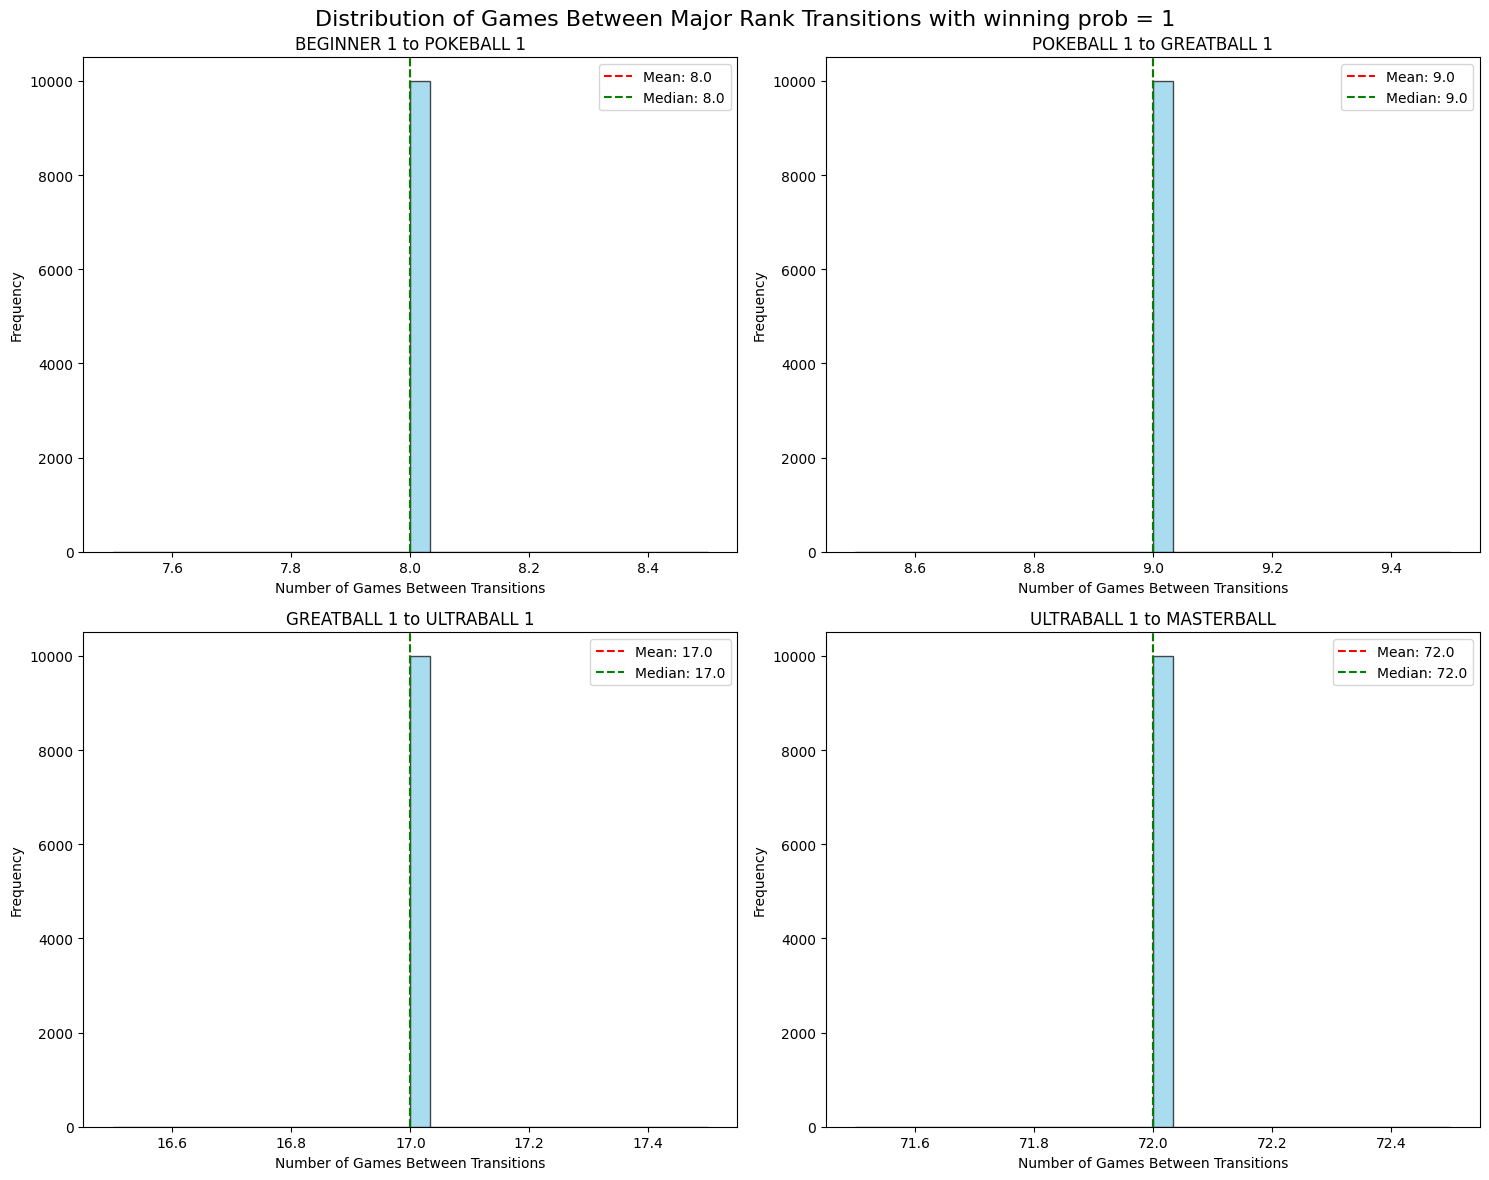

In [10]:
def run_single_simulation(n_games, prob = 0.5):
    """Run a single simulation of n_games and return rank progression data."""
    match_results = np.random.binomial(1, prob, n_games)
    results = calculate_rank_progression(match_results)
    return results

def get_major_rank_transitions(rank_history):
    """Get the match numbers for major rank transitions."""
    transitions = {
        'BEGINNER_1_to_POKEBALL_1': None,
        'POKEBALL_1_to_GREATBALL_1': None,
        'GREATBALL_1_to_ULTRABALL_1': None,
        'ULTRABALL_1_to_MASTERBALL': None
    }
    
    # Track the last transition point
    last_transition = 0
    
    for i, rank in enumerate(rank_history):
        if rank == 'POKEBALL_1' and transitions['BEGINNER_1_to_POKEBALL_1'] is None:
            transitions['BEGINNER_1_to_POKEBALL_1'] = i + 1 - last_transition
            last_transition = i + 1
        elif rank == 'GREATBALL_1' and transitions['POKEBALL_1_to_GREATBALL_1'] is None:
            transitions['POKEBALL_1_to_GREATBALL_1'] = i + 1 - last_transition
            last_transition = i + 1
        elif rank == 'ULTRABALL_1' and transitions['GREATBALL_1_to_ULTRABALL_1'] is None:
            transitions['GREATBALL_1_to_ULTRABALL_1'] = i + 1 - last_transition
            last_transition = i + 1
        elif rank == 'MASTERBALL' and transitions['ULTRABALL_1_to_MASTERBALL'] is None:
            transitions['ULTRABALL_1_to_MASTERBALL'] = i + 1 - last_transition
            last_transition = i + 1
    
    return transitions

def run_multiple_simulations(n_simulations, n_games, prob = 0.5):
    """Run multiple simulations and collect rank transition data."""
    transition_data = {
        'BEGINNER_1_to_POKEBALL_1': [],
        'POKEBALL_1_to_GREATBALL_1': [],
        'GREATBALL_1_to_ULTRABALL_1': [],
        'ULTRABALL_1_to_MASTERBALL': []
    }
    
    for _ in range(n_simulations):
        results = run_single_simulation(n_games, prob)
        transitions = get_major_rank_transitions(results['rank_history'])
        
        for key in transition_data:
            if transitions[key] is not None:
                transition_data[key].append(transitions[key])
    
    return transition_data

def plot_transition_distributions(transition_data, prob = 0.5):
    """Plot distributions of games needed for each major rank transition."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle('Distribution of Games Between Major Rank Transitions with winning prob = '+str(prob), fontsize=16)
    
    axes = axes.flatten()
    for idx, (transition, data) in enumerate(transition_data.items()):
        if data:  # Only plot if we have data
            ax = axes[idx]
            ax.hist(data, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
            ax.set_title(transition.replace('_', ' '))
            ax.set_xlabel('Number of Games Between Transitions')
            ax.set_ylabel('Frequency')
            
            # Add mean and median lines
            mean_games = np.mean(data)
            median_games = np.median(data)
            ax.axvline(mean_games, color='red', linestyle='--', label=f'Mean: {mean_games:.1f}')
            ax.axvline(median_games, color='green', linestyle='--', label=f'Median: {median_games:.1f}')
            ax.legend()
    
    plt.tight_layout()
    plt.show()

# Run simulations and plot distributions
n_simulations = 10000  # Number of simulations
n_games = 2000       # Maximum number of games per simulation
prob = 1
print(f"Running {n_simulations} simulations with {n_games} games each...")
transition_data = run_multiple_simulations(n_simulations, n_games, prob)
'''
# Print summary statistics
print("\nSummary Statistics for Rank Transitions:")
for transition, data in transition_data.items():
    if data:
        print(f"\n{transition.replace('_', ' ')}:")
        print(f"Mean games needed: {np.mean(data):.1f}")
        print(f"Median games needed: {np.median(data):.1f}")
        print(f"Min games needed: {min(data)}")
        print(f"Max games needed: {max(data)}")
        print(f"Number of successful transitions: {len(data)}")
        print(f"Success rate: {(len(data)/n_simulations)*100:.1f}%")
'''
# Plot the distributions
plot_transition_distributions(transition_data, prob) 

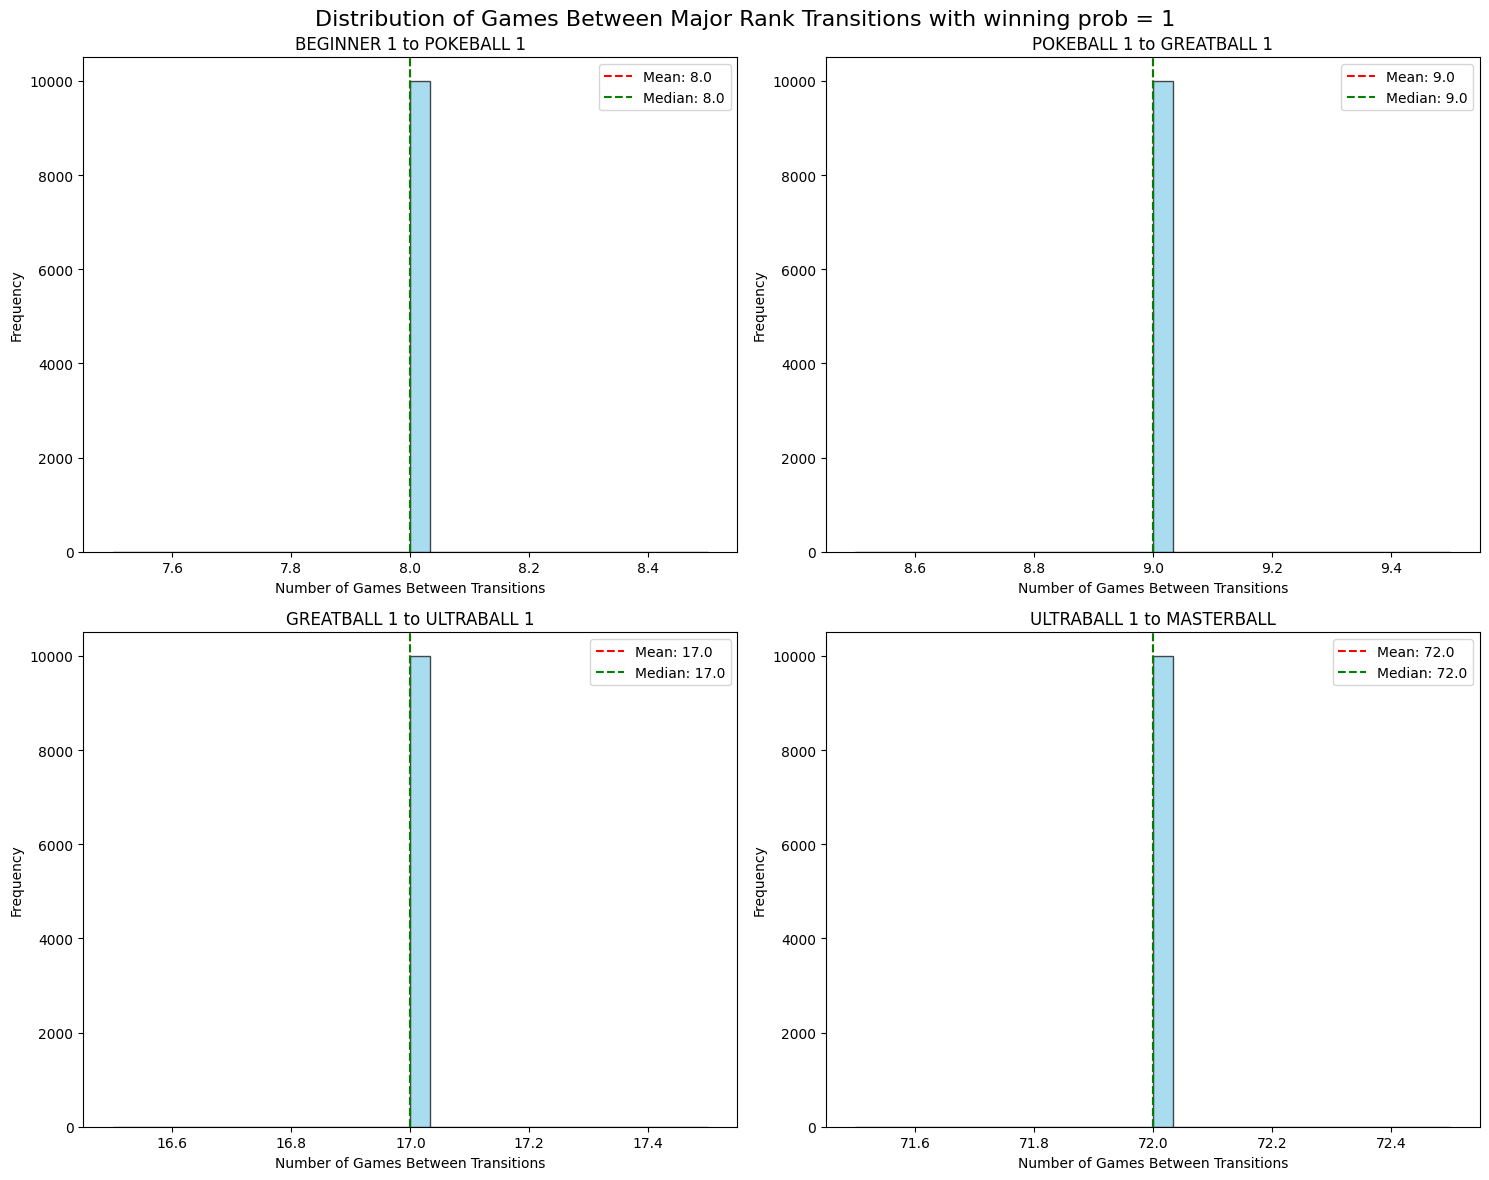

Running simulations for win probability: 0.01
Running simulations for win probability: 0.06
Running simulations for win probability: 0.11
Running simulations for win probability: 0.17
Running simulations for win probability: 0.22
Running simulations for win probability: 0.27
Running simulations for win probability: 0.32
Running simulations for win probability: 0.37
Running simulations for win probability: 0.43
Running simulations for win probability: 0.48
Running simulations for win probability: 0.53
Running simulations for win probability: 0.58
Running simulations for win probability: 0.64
Running simulations for win probability: 0.69
Running simulations for win probability: 0.74
Running simulations for win probability: 0.79
Running simulations for win probability: 0.84
Running simulations for win probability: 0.90
Running simulations for win probability: 0.95
Running simulations for win probability: 1.00


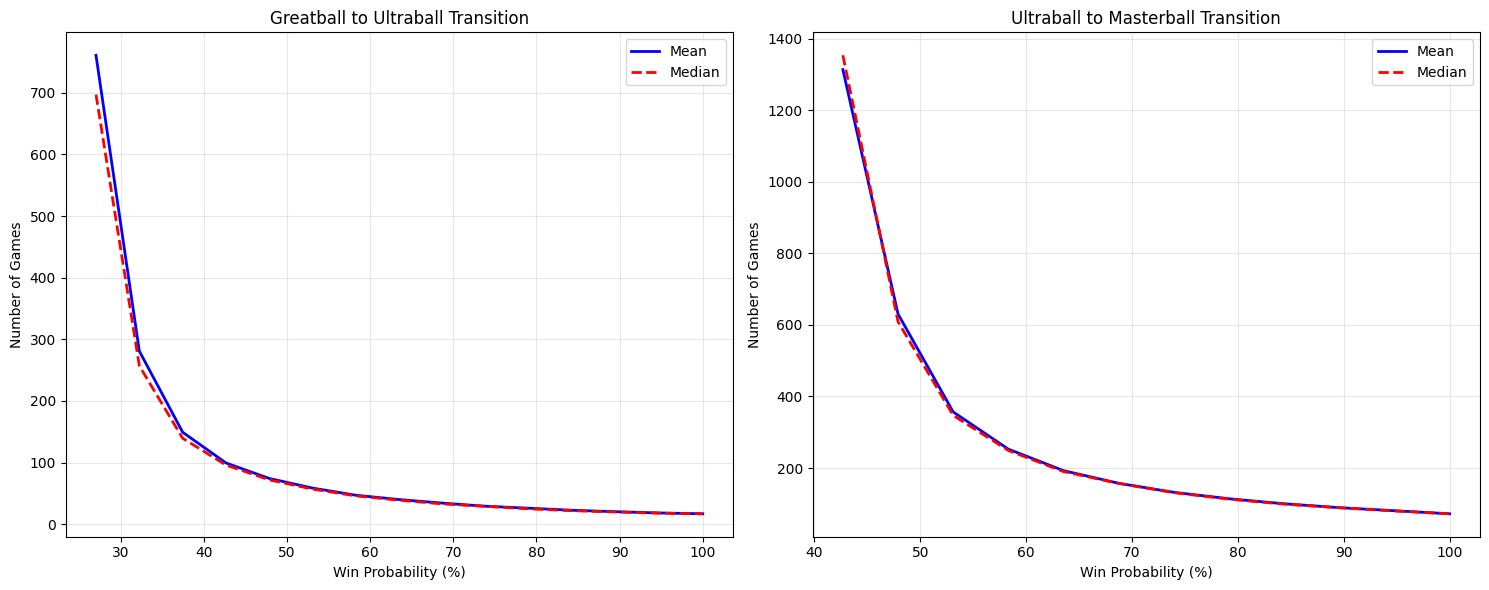

In [12]:
# Plot the distributions
plot_transition_distributions(transition_data, prob) 

# %%
# Analyze rank transitions across different win probabilities
win_probs = np.linspace(0.01, 1.0, 20)  # 20 evenly spaced probabilities from 1% to 100%
n_simulations = 1000  # Reduced number of simulations for faster computation
n_games = 2000

# Store results for each probability
great_to_ultra_means = []
great_to_ultra_medians = []
ultra_to_master_means = []
ultra_to_master_medians = []

for prob in win_probs:
    print(f"Running simulations for win probability: {prob:.2f}")
    transition_data = run_multiple_simulations(n_simulations, n_games, prob)
    
    # Extract data for Greatball to Ultraball transition
    if transition_data['GREATBALL_1_to_ULTRABALL_1']:
        great_to_ultra_means.append(np.mean(transition_data['GREATBALL_1_to_ULTRABALL_1']))
        great_to_ultra_medians.append(np.median(transition_data['GREATBALL_1_to_ULTRABALL_1']))
    else:
        great_to_ultra_means.append(np.nan)
        great_to_ultra_medians.append(np.nan)
    
    # Extract data for Ultraball to Masterball transition
    if transition_data['ULTRABALL_1_to_MASTERBALL']:
        ultra_to_master_means.append(np.mean(transition_data['ULTRABALL_1_to_MASTERBALL']))
        ultra_to_master_medians.append(np.median(transition_data['ULTRABALL_1_to_MASTERBALL']))
    else:
        ultra_to_master_means.append(np.nan)
        ultra_to_master_medians.append(np.nan)

# Create plots
plt.figure(figsize=(15, 6))

# Plot for Greatball to Ultraball transition
plt.subplot(1, 2, 1)
plt.plot(win_probs * 100, great_to_ultra_means, 'b-', label='Mean', linewidth=2)
plt.plot(win_probs * 100, great_to_ultra_medians, 'r--', label='Median', linewidth=2)
plt.title('Greatball to Ultraball Transition')
plt.xlabel('Win Probability (%)')
plt.ylabel('Number of Games')
plt.grid(True, alpha=0.3)
plt.legend()

# Plot for Ultraball to Masterball transition
plt.subplot(1, 2, 2)
plt.plot(win_probs * 100, ultra_to_master_means, 'b-', label='Mean', linewidth=2)
plt.plot(win_probs * 100, ultra_to_master_medians, 'r--', label='Median', linewidth=2)
plt.title('Ultraball to Masterball Transition')
plt.xlabel('Win Probability (%)')
plt.ylabel('Number of Games')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()